<a href="https://colab.research.google.com/github/imanand002/Applied-ML-Lab/blob/main/ML_Exp1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Experiment 1: House Price Prediction
**Dataset:** `Housing.csv` (columns: `area`, `price`)

This notebook walks through a complete, minimal pipeline:
1. Import data
2. Basic preprocessing
3. Visualize the data (scatter plot)
4. Train/test split
5. Train a Simple Linear Regression model
6. Report slope & intercept
7. Report accuracy metrics
8. Visualize the regression line
9. Predict price for a new area value

> **Note:** Since we're skipping feature management, this notebook uses a single feature (`area`) to predict `price`. If your CSV has more numeric columns, this same pipeline still works — just make sure `area` and `price` are present, or change the column names in Step 2.

## Step 0: Install & Import Libraries

In [ ]:
# Core libraries for data handling, visualization and modeling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make plots a bit nicer

## Step 1: Import the Data

**On Google Colab**, upload `Housing.csv` first. Run the cell below — it will open a file picker.
(If you're running locally / the file is already in your working directory, you can skip the upload cell and just load it directly.)

In [ ]:

# Load the dataset
df = pd.read_csv("/content/Housing.csv")

# Quick look at the data
print("Shape:", df.shape)
print(df.head())
print(df.describe())
print(df.info())

Shape: (545, 13)
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  
              price          area    bedrooms   bathrooms     stories  \
count  5.

## Step 2: Basic Data Preprocessing

We'll do the essentials only:
- Check for missing values
- Check data types
- Basic descriptive statistics
- Select the columns we need (`area` as feature, `price` as target)
- Drop duplicates / missing rows if any

In [ ]:
# Check info and missing values
print("\nMissing values per column:\n", df.isnull().sum())


Missing values per column:
 price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [ ]:
# Keep only the columns needed for this simple regression
data = df[['area', 'price']].copy()

# Drop any missing or duplicate rows
data = data.dropna()
data = data.drop_duplicates()

print("Final shape after cleaning:", data.shape)
data.head()

Final shape after cleaning: (532, 2)


,area,price
0,7420,13300000
1,8960,12250000
2,9960,12250000
3,7500,12215000
4,7420,11410000


## Step 3: Visualize the Data (Scatter Plot)

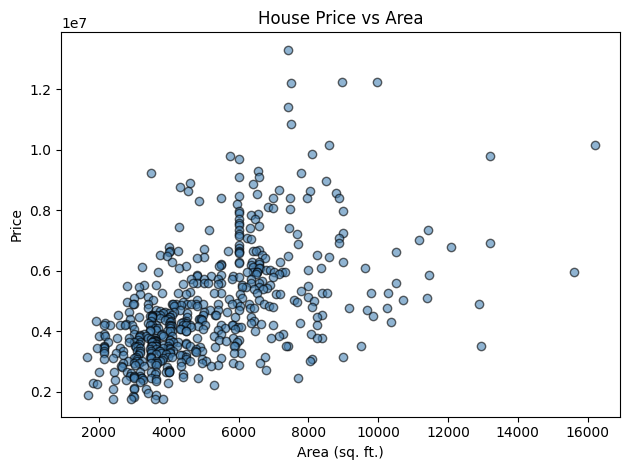

In [ ]:
plt.scatter(data['area'], data['price'], color='steelblue', alpha=0.6, edgecolor='k')
plt.title('House Price vs Area')
plt.xlabel('Area (sq. ft.)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

## Step 4: Train-Test Split

We split the data into training (80%) and testing (20%) sets.

In [ ]:
X = data[['area']]   # Feature (kept as 2D DataFrame for sklearn)
y = data['price']     # Target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])
print(X_train.head())
print(y_train.head())

Training samples: 425
Testing samples : 107
     area
306  4840
413  1950
458  3850
319  3000
145  5000
306    4165000
413    3430000
458    3115000
319    4060000
145    5600000
Name: price, dtype: int64


## Step 5: Train the Linear Regression Model

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


## Step 6: Slope and Intercept

For simple linear regression: `price = slope * area + intercept`

In [ ]:
slope = model.coef_[0]
intercept = model.intercept_

print(f"Slope (coefficient)  : {slope:.4f}")
print(f"Intercept             : {intercept:.4f}")
print(f"\nEquation: price = {slope:.4f} * area + ({intercept:.4f})")

Slope (coefficient)  : 441.5876
Intercept             : 2450352.7349

Equation: price = 441.5876 * area + (2450352.7349)


## Step 7: Accuracy Metrics

We evaluate the model on the **test set** using:
- **MAE** (Mean Absolute Error)
- **MSE** (Mean Squared Error)
- **RMSE** (Root Mean Squared Error)
- **R² Score** (coefficient of determination — how well the model explains variance in price)

In [ ]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE)  : {mae:,.2f}")
print(f"Mean Squared Error (MSE)   : {mse:,.2f}")
print(f"Root Mean Squared Error    : {rmse:,.2f}")
print(f"R² Score                   : {r2:.4f}")

Mean Absolute Error (MAE)  : 1,424,905.44
Mean Squared Error (MSE)   : 3,547,685,936,845.33
Root Mean Squared Error    : 1,883,530.18
R² Score                   : 0.2770


## Step 8: Visualize the Regression Line

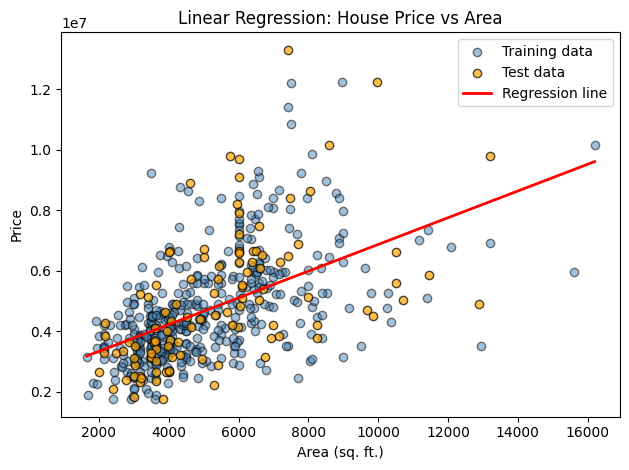

In [ ]:
plt.scatter(X_train, y_train, color='steelblue', alpha=0.5, edgecolor='k', label='Training data')
plt.scatter(X_test, y_test, color='orange', alpha=0.7, edgecolor='k', label='Test data')

# Regression line across the full range of area values
x_range = np.linspace(data['area'].min(), data['area'].max(), 100).reshape(-1, 1)
y_range_pred = model.predict(pd.DataFrame(x_range, columns=['area']))

plt.plot(x_range, y_range_pred, color='red', linewidth=2, label='Regression line')

plt.title('Linear Regression: House Price vs Area')
plt.xlabel('Area (sq. ft.)')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

## Step 9: Predict Price for a New House

Use the trained model to predict the price of a house given its area.

In [ ]:
def predict_price(area_value):
    """Predict house price given an area (in sq. ft.) using the trained model."""
    input_df = pd.DataFrame([[area_value]], columns=['area'])
    predicted_price = model.predict(input_df)[0]
    return predicted_price

# Example usage
new_area = 3000   # change this value to any area you want to test
predicted = predict_price(new_area)
print(f"Predicted price for area = {new_area} sq. ft. : {predicted:,.2f}")

Predicted price for area = 3000 sq. ft. : 3,775,115.53


---
### Summary
- Trained a simple linear regression model on `area` → `price`.
- Reported slope, intercept, and evaluation metrics (MAE, MSE, RMSE, R²).
- Visualized both the raw data and the fitted regression line.
- Provided a reusable `predict_price()` function for new predictions.

# Multiple Linear Regression

In [ ]:
X_MLR = df[['area', 'bedrooms', 'bathrooms', 'stories']]
y_MLR = df['price']

In [ ]:
# Fix the train-test split by providing both features and target
X_train_MLR, X_test_MLR, y_train_MLR, y_test_MLR = train_test_split(
    X_MLR, y_MLR, test_size=0.2, random_state=42
)

print("Training samples (MLR):", X_train_MLR.shape[0])
print("Testing samples (MLR) :", X_test_MLR.shape[0])

Training samples (MLR): 436
Testing samples (MLR) : 109


In [ ]:
# Define and train the Multiple Linear Regression model
modle_MLR = LinearRegression()
modle_MLR.fit(X_train_MLR, y_train_MLR)

# Make predictions
y_pred_MLR = modle_MLR.predict(X_test_MLR)

# Calculate metrics
mae_MLR = mean_absolute_error(y_test_MLR, y_pred_MLR)
rmse_MLR = np.sqrt(mean_squared_error(y_test_MLR, y_pred_MLR))
r2_MLR = r2_score(y_test_MLR, y_pred_MLR)

print("--- Multiple Linear Regression Results ---")
print(f"MAE: {mae_MLR:,.2f}")
print(f"RMSE: {rmse_MLR:,.2f}")
print(f"R2 Score: {r2_MLR:.4f}")

--- Multiple Linear Regression Results ---
MAE: 1,158,970.48
RMSE: 1,567,718.61
R2 Score: 0.5138


## Step 10: Multi-Feature Prediction
Now we can use the trained MLR model to predict prices based on multiple inputs.

In [ ]:
def predict_house_price_mlr(area, bedrooms, bathrooms, stories):
    """Predict house price using multiple features."""
    features = pd.DataFrame([[area, bedrooms, bathrooms, stories]],
                            columns=['area', 'bedrooms', 'bathrooms', 'stories'])
    prediction = modle_MLR.predict(features)[0]
    return prediction

# Test with specific values
test_area = 3000
test_beds = 3
test_baths = 2
test_stories = 2

price_mlr = predict_house_price_mlr(test_area, test_beds, test_baths, test_stories)
print(f"Predicted Price for {test_area}sqft, {test_beds}BR, {test_baths}BA: ${price_mlr:,.2f}")

Predicted Price for 3000sqft, 3BR, 2BA: $4,990,763.43


## Step 10: Multi-Feature Prediction
Now we can predict prices using all four features.

## Step 11: Visualize Actual vs Predicted (MLR)
This plot helps us see how close our predictions are to the true values. The closer the points are to the diagonal line, the better the model.

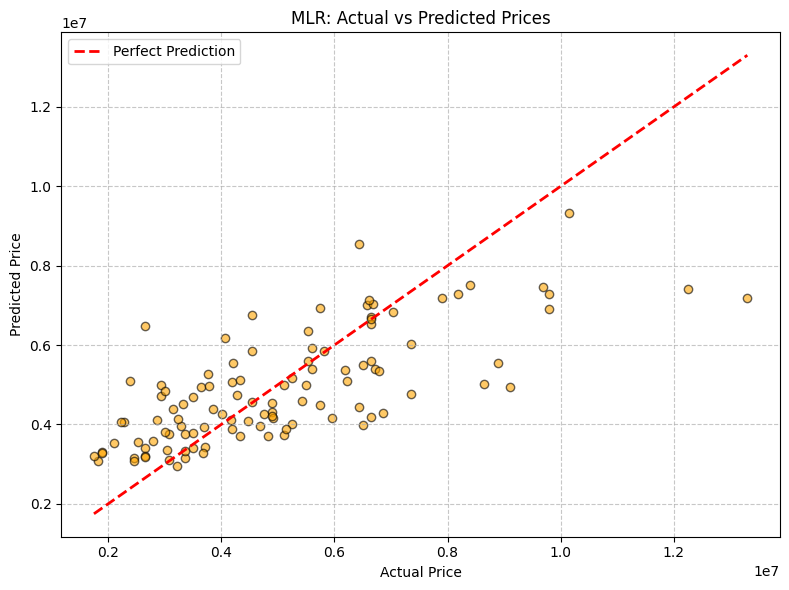

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test_MLR, y_pred_MLR, color='orange', alpha=0.6, edgecolor='k')

# Reference line for perfect prediction
max_val = max(y_test_MLR.max(), y_pred_MLR.max())
min_val = min(y_test_MLR.min(), y_pred_MLR.min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2, label='Perfect Prediction')

plt.title('MLR: Actual vs Predicted Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Step 12: Polynomial Regression
Sometimes the relationship between variables isn't a straight line. Polynomial regression creates non-linear features (like $area^2$) to fit a curve to the data.

In [ ]:
# 0. Ensure base data and split exist
data = df[['area', 'price']].dropna().drop_duplicates()
X = data[['area']]
y = data['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Create Polynomial Features (Degree 2)
poly = PolynomialFeatures(degree=2)
X_poly_train = poly.fit_transform(X_train)
X_poly_test = poly.transform(X_test)

# 2. Train the model
model_poly = LinearRegression()
model_poly.fit(X_poly_train, y_train)

# 3. Predict and Evaluate
y_pred_poly = model_poly.predict(X_poly_test)
r2_poly = r2_score(y_test, y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))

print(f"Polynomial Regression (Degree 2) Results:")
print(f"RMSE: {rmse_poly:,.2f}")
print(f"R2 Score: {r2_poly:.4f}")

Polynomial Regression (Degree 2) Results:
RMSE: 1,822,937.22
R2 Score: 0.3228


### Visualize the Polynomial Curve

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


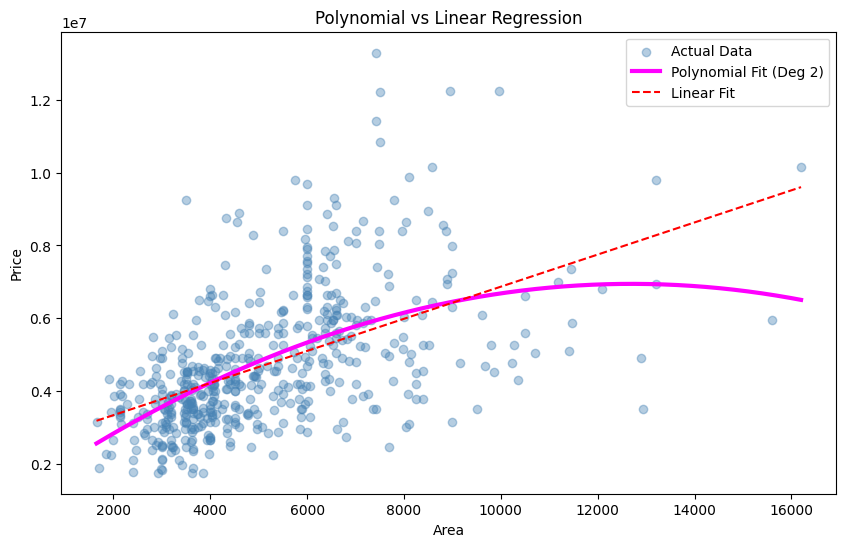

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(data['area'], data['price'], color='steelblue', alpha=0.4, label='Actual Data')

# Generate points for the curve
x_coord = np.linspace(data['area'].min(), data['area'].max(), 200).reshape(-1, 1)
x_coord_poly = poly.transform(x_coord)
y_coord_poly = model_poly.predict(x_coord_poly)

# Also get linear fit for comparison plot
model_lin = LinearRegression().fit(X_train, y_train)
y_coord_lin = model_lin.predict(x_coord)

plt.plot(x_coord, y_coord_poly, color='magenta', linewidth=3, label='Polynomial Fit (Deg 2)')
plt.plot(x_coord, y_coord_lin, color='red', linestyle='--', label='Linear Fit')

plt.title('Polynomial vs Linear Regression')
plt.xlabel('Area')
plt.ylabel('Price')
plt.legend()
plt.show()

### Interactive Polynomial Regression Explorer
Use the slider below to change the **Degree** of the polynomial and observe how the model complexity affects the fit.

In [ ]:
import ipywidgets as widgets
from ipywidgets import interact

def plot_polynomial_degree(degree):
    # 1. Transform features
    poly_feat = PolynomialFeatures(degree=degree)
    X_poly_train = poly_feat.fit_transform(X_train)

    # 2. Train model
    model = LinearRegression()
    model.fit(X_poly_train, y_train)

    # 3. Calculate Performance
    y_pred = model.predict(poly_feat.transform(X_test))
    r2 = r2_score(y_test, y_pred)

    # 4. Visualization
    plt.figure(figsize=(10, 6))
    plt.scatter(data['area'], data['price'], color='steelblue', alpha=0.4, label='Actual Data')

    x_range = np.linspace(data['area'].min(), data['area'].max(), 300).reshape(-1, 1)
    y_range_pred = model.predict(poly_feat.transform(x_range))

    plt.plot(x_range, y_range_pred, color='red', linewidth=3, label=f'Degree {degree} Fit')

    plt.title(f'Polynomial Regression (Degree {degree})\nR² Score: {r2:.4f}')
    plt.xlabel('Area (sq. ft.)')
    plt.ylabel('Price')
    plt.legend()
    plt.ylim(0, data['price'].max() * 1.1)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

# Create interactive slider
interact(plot_polynomial_degree, degree=widgets.IntSlider(min=1, max=10, step=1, value=2));

interactive(children=(IntSlider(value=2, description='degree', max=10, min=1), Output()), _dom_classes=('widge…